# Experiments: Feature-Group Ablation and Preprocessing Order

This notebook reads existing team files as read-only and writes experiment outputs only to `figures_exp/` and `results_exp/`.

GIT STATUS BEFORE
## Experiments_feat
?? .idea/
?? experiments.ipynb

GIT DIFF --STAT BEFORE
<empty>
Hashed existing files at start: 6

STEP 0 DISCOVERY
modeling_table shape: (24566, 55)
target column: podium
key columns present: ['raceId', 'driverId', 'year', 'constructorId']
columns: ['resultId', 'raceId', 'driverId', 'constructorId', 'circuitId', 'year', 'round', 'race_order', 'podium', 'grid_clean', 'grid_rel', 'pole', 'pit_lane_start', 'front_row', 'team_best_grid', 'grid_vs_team', 'quali_pos', 'quali_pos_rel', 'quali_gap_pct', 'q1_gap_pct', 'grid_minus_quali', 'drv_podium_rate_w3', 'drv_podium_rate_w5', 'drv_podium_rate_w10', 'drv_finish_rel_w3', 'drv_finish_rel_w5', 'drv_finish_rel_w10', 'drv_career_starts', 'drv_career_podium_rate', 'team_podium_rate_w3', 'team_podium_rate_w5', 'team_podium_rate_w10', 'team_finish_rel_w3', 'team_finish_rel_w5', 'team_finish_rel_w10', 'drv_dnf_rate_w3', 'drv_dnf_rate_w5', 'drv_dnf_rate_w10', 'team_dnf_rate_w3', 'team_dnf_rate_w5', 'team_dnf_rate

,group,feature
0,grid,grid_clean
1,grid,pole
2,grid,pit_lane_start
3,grid,front_row
4,grid,team_best_grid
5,grid,grid_vs_team
6,qualifying,quali_pos
7,qualifying,quali_gap_pct
8,qualifying,q1_gap_pct
9,qualifying,grid_minus_quali


feature_dictionary shape: (29, 6)


,feature,group,definition,valid_at_cutoff_because,sources,coverage_train
0,grid_clean,grid,Starting slot; pit-lane start (grid 0) mapped ...,grid is set after qualifying (incl. penalties),results,1.000000
1,pole,grid,1 if the driver starts from pole (grid_clean =...,grid known,results,1.000000
2,pit_lane_start,grid,1 if the driver starts from the pit lane / no ...,known when the grid is set,results,1.000000
3,front_row,grid,1 if grid_clean <= 2,derived from the grid,results,1.000000
4,team_best_grid,grid,Best grid slot of the driver's team in this race,grid of both cars known,results,1.000000
5,grid_vs_team,grid,grid_clean minus the team's mean grid in this ...,grid known,results,1.000000
6,quali_pos,qualifying,Qualifying classification,qualifying ends before the cutoff,qualifying,0.369324
7,quali_gap_pct,qualifying,% slower than the fastest time of the LAST qua...,qualifying times known after qualifying,qualifying,0.363486
8,q1_gap_pct,qualifying,% slower than the fastest Q1 time of the session,Q1 times known after qualifying,qualifying,0.363486
9,grid_minus_quali,qualifying,grid - qualifying position (penalty signal),both known at the cutoff,"results, qualifying",0.368477


Notebook text/JSON inspection summary:
{
  "feature_engineering.ipynb": {
    "mentions_split_rule": true,
    "uses_simple_imputer": true,
    "uses_standard_scaler": true,
    "uses_validation_f1_threshold": false,
    "mentions_seed_42": true
  },
  "training2.ipynb": {
    "mentions_split_rule": true,
    "uses_simple_imputer": true,
    "uses_standard_scaler": true,
    "uses_validation_f1_threshold": true,
    "mentions_seed_42": true
  }
}
Final model JSON:
{
  "final_model": "nn",
  "label": "Shallow NN",
  "threshold": 0.7384114937517937
}
Saved model JSON summaries:
logreg {
  "model": "Logistic regression",
  "params": {
    "C": 0.01
  },
  "threshold": 0.6702616582499759,
  "val": {
    "roc_auc": 0.9330939650574354,
    "pr_auc": 0.7371144336487154,
    "f1": 0.7109375,
    "precision": 0.6546762589928058,
    "recall": 0.7777777777777778,
    "top3_precision": 0.6837606837606838,
    "threshold": 0.6702616582499759
  }
}
rf {
  "model": "Random forest",
  "params": {
   

...


STEP 1 BASELINE
Split row counts:
        rows  races  first_year  last_year
split                                     
train  22441   1007        1950       2019
val      774     39        2020       2021
test    1351     68        2022       2024
Expected validation+test rows from saved prediction files: 2125


,mine_val,saved_val,abs_diff
roc_auc,0.933094,0.933094,0.000000e+00
pr_auc,0.737114,0.737114,0.000000e+00
f1,0.710938,0.710938,0.000000e+00
precision,0.654676,0.654676,0.000000e+00
recall,0.777778,0.777778,0.000000e+00
top3_precision,0.683761,0.683761,0.000000e+00
threshold,0.670262,0.670262,7.882583e-15


Baseline reproduction max metric diff: 0.00000000

STEP 2 FEATURE-GROUP ABLATION
Rows with at least one missing qualifying value: 14368


,model,run_type,group,split,n_features,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,f1_std,precision_mean,precision_std,recall_mean,recall_std,top3_precision_mean,top3_precision_std,threshold_mean,threshold_std
2,logreg,full,full,val,29,0.9331,NaN,0.7371,NaN,0.7109,NaN,0.6547,NaN,0.7778,NaN,0.6838,NaN,0.6703,NaN
5,logreg,grid_reference,grid,val,6,0.9170,NaN,0.6664,NaN,0.7043,NaN,0.7168,NaN,0.6923,NaN,0.7094,NaN,0.7812,NaN
8,logreg,leave_one_group_out,circuit_history,val,26,0.9333,NaN,0.7342,NaN,0.7109,NaN,0.6547,NaN,0.7778,NaN,0.6838,NaN,0.6688,NaN
11,logreg,leave_one_group_out,constructor_form,val,27,0.9334,NaN,0.7397,NaN,0.7087,NaN,0.6569,NaN,0.7692,NaN,0.6838,NaN,0.6724,NaN
14,logreg,leave_one_group_out,context,val,25,0.9325,NaN,0.7365,NaN,0.7063,NaN,0.6593,NaN,0.7607,NaN,0.6838,NaN,0.6770,NaN
17,logreg,leave_one_group_out,driver_form,val,25,0.9314,NaN,0.7270,NaN,0.7115,NaN,0.6618,NaN,0.7692,NaN,0.6923,NaN,0.7098,NaN
20,logreg,leave_one_group_out,grid,val,23,0.9280,NaN,0.7270,NaN,0.6973,NaN,0.6319,NaN,0.7778,NaN,0.6752,NaN,0.6392,NaN
23,logreg,leave_one_group_out,qualifying,val,25,0.9273,NaN,0.7201,NaN,0.7063,NaN,0.6593,NaN,0.7607,NaN,0.6752,NaN,0.6995,NaN
26,logreg,leave_one_group_out,standings,val,23,0.9322,NaN,0.7314,NaN,0.7082,NaN,0.6500,NaN,0.7778,NaN,0.6838,NaN,0.6721,NaN
29,logreg,only_this_group,circuit_history,val,3,0.7142,NaN,0.3246,NaN,0.4076,NaN,0.3249,NaN,0.5470,NaN,0.3761,NaN,0.5127,NaN


,model,group,n_features,val_pr_auc_removed_mean,delta_pr_auc_vs_full,delta_pr_auc_ci_low,delta_pr_auc_ci_high,val_roc_auc_removed_mean,delta_roc_auc_vs_full,delta_roc_auc_ci_low,delta_roc_auc_ci_high
1,logreg,qualifying,4,0.7201,-0.0170,-0.0308,-0.0012,0.9273,-0.0058,-0.0100,-0.0016
2,logreg,driver_form,4,0.7270,-0.0102,-0.0264,0.0091,0.9314,-0.0017,-0.0041,0.0002
0,logreg,grid,6,0.7270,-0.0101,-0.0264,0.0035,0.9280,-0.0051,-0.0109,0.0007
4,logreg,standings,6,0.7314,-0.0058,-0.0211,0.0077,0.9322,-0.0009,-0.0029,0.0010
5,logreg,circuit_history,3,0.7342,-0.0029,-0.0094,0.0014,0.9333,0.0002,-0.0005,0.0008
6,logreg,context,4,0.7365,-0.0006,-0.0074,0.0068,0.9325,-0.0006,-0.0020,0.0008
3,logreg,constructor_form,2,0.7397,0.0026,-0.0053,0.0096,0.9334,0.0003,-0.0012,0.0019
8,nn,qualifying,4,0.7021,-0.0111,-0.0190,0.0222,0.9249,-0.0043,-0.0083,0.0027
9,nn,driver_form,4,0.7042,-0.0089,-0.0145,0.0269,0.9286,-0.0006,-0.0043,0.0062
13,nn,context,4,0.7136,0.0005,-0.0188,0.0265,0.9300,0.0008,-0.0046,0.0050


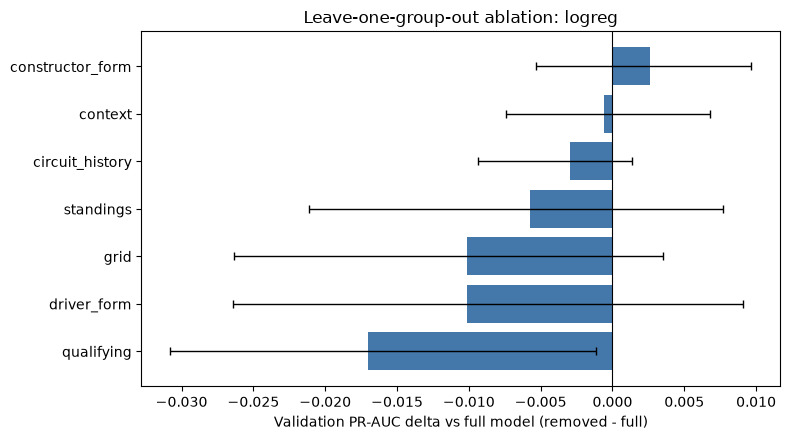

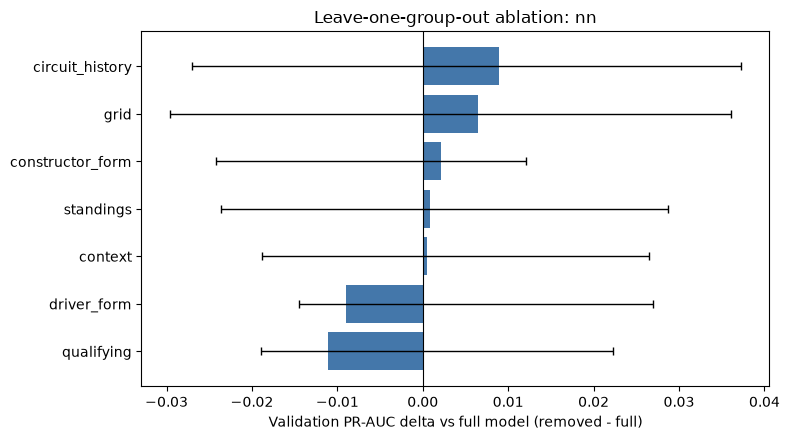

Permutation/SHAP-like files found for comparison:
C:/Users/lenovo/Formula-1-Podium-Prediction-Companion/figures_xai/local_shap_vs_lime_borderline.png
C:/Users/lenovo/Formula-1-Podium-Prediction-Companion/figures_xai/local_shap_vs_lime_confident_hit.png
C:/Users/lenovo/Formula-1-Podium-Prediction-Companion/figures_xai/local_shap_vs_lime_false_alarm.png
C:/Users/lenovo/Formula-1-Podium-Prediction-Companion/figures_xai/local_shap_vs_lime_missed_podium.png
C:/Users/lenovo/Formula-1-Podium-Prediction-Companion/figures_xai/perm_vs_shap.png
C:/Users/lenovo/Formula-1-Podium-Prediction-Companion/figures_xai/shap_bar.png
C:/Users/lenovo/Formula-1-Podium-Prediction-Companion/figures_xai/shap_beeswarm.png
C:/Users/lenovo/Formula-1-Podium-Prediction-Companion/figures_xai/shap_beeswarm_logreg.png
C:/Users/lenovo/Formula-1-Podium-Prediction-Companion/figures_xai/shap_beeswarm_rf.png
C:/Users/lenovo/Formula-1-Podium-Prediction-Companion/figures_xai/shap_beeswarm_xgb.png
C:/Users/lenovo/Formula-1-Podiu

,experiment,pipeline,model,seed,split,roc_auc,pr_auc,f1,precision,recall,top3_precision,threshold
0,split_fit_scope,correct_split_then_fit,logreg,42,train,0.9025,0.5734,0.5840,0.4862,0.7309,0.5588,0.6703
1,split_fit_scope,correct_split_then_fit,logreg,42,val,0.9331,0.7371,0.7109,0.6547,0.7778,0.6838,0.6703
2,split_fit_scope,correct_split_then_fit,logreg,42,test,0.9300,0.7182,0.6629,0.5401,0.8578,0.6618,0.6703
3,split_fit_scope,invalid_fit_then_split,logreg,42,train,0.9025,0.5733,0.5828,0.4845,0.7312,0.5588,0.6684
4,split_fit_scope,invalid_fit_then_split,logreg,42,val,0.9329,0.7362,0.7082,0.6500,0.7778,0.6838,0.6684
5,split_fit_scope,invalid_fit_then_split,logreg,42,test,0.9304,0.7186,0.6591,0.5352,0.8578,0.6618,0.6684


The fit-then-split row is intentionally invalid because imputer/scaler statistics see validation/test rows before evaluation.


,experiment,pipeline,model,seed,split,roc_auc,pr_auc,f1,precision,recall,top3_precision,threshold
0,impute_scale_order,impute_then_scale,logreg,42,train,0.9025,0.5734,0.5840,0.4862,0.7309,0.5588,0.6703
1,impute_scale_order,impute_then_scale,logreg,42,val,0.9331,0.7371,0.7109,0.6547,0.7778,0.6838,0.6703
2,impute_scale_order,impute_then_scale,logreg,42,test,0.9300,0.7182,0.6629,0.5401,0.8578,0.6618,0.6703
3,impute_scale_order,scale_then_impute,logreg,42,train,0.9023,0.5725,0.5839,0.4913,0.7196,0.5574,0.6807
4,impute_scale_order,scale_then_impute,logreg,42,val,0.9318,0.7337,0.7087,0.6569,0.7692,0.6838,0.6807
5,impute_scale_order,scale_then_impute,logreg,42,test,0.9317,0.7188,0.6667,0.5472,0.8529,0.6618,0.6807


,stage,column,mean,std,min,max
0,raw_train,grid_clean,11.9106,6.8235,1.0000,34.0000
1,raw_train,quali_pos,11.3450,6.3588,1.0000,26.0000
2,correct_impute_then_scale,grid_clean,-0.0000,1.0000,-1.5990,3.2372
3,correct_impute_then_scale,quali_pos,-0.0000,1.0000,-2.6183,3.8451
4,scale_then_impute,grid_clean,-0.0000,1.0000,-1.5990,3.2372
5,scale_then_impute,quali_pos,-0.0342,0.6083,-1.6269,2.3047
6,leaky_full_impute_then_scale_on_train,grid_clean,0.0179,1.0107,-1.5982,3.2897
7,leaky_full_impute_then_scale_on_train,quali_pos,0.0138,0.9503,-2.4744,3.6678


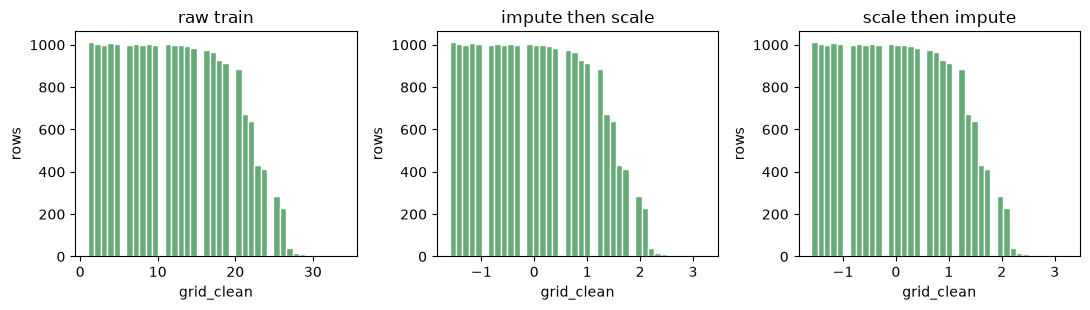

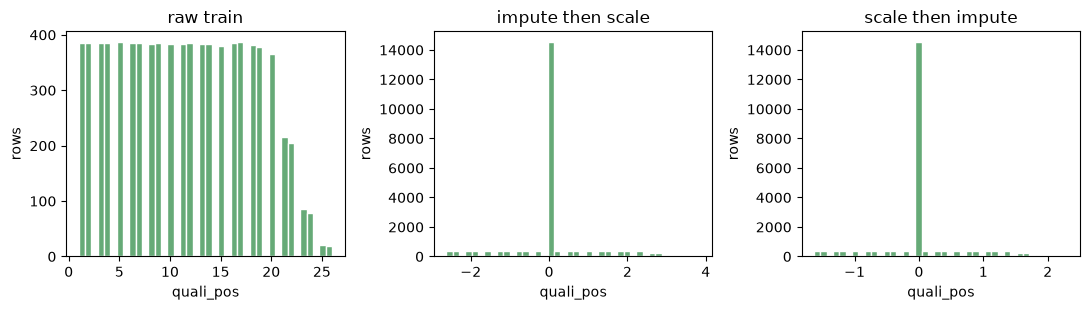


STEP 4 WRAP-UP


,file,start_sha256,end_sha256,unchanged
0,C:/Users/lenovo/Formula-1-Podium-Prediction-Co...,9e3f8317cfa43b934558742356b4dd41fc5cb4b55332a1...,9e3f8317cfa43b934558742356b4dd41fc5cb4b55332a1...,True
1,C:/Users/lenovo/Formula-1-Podium-Prediction-Co...,ff443da2b398f847981163c57952d17a7f1b289341f1af...,ff443da2b398f847981163c57952d17a7f1b289341f1af...,True
2,C:/Users/lenovo/Formula-1-Podium-Prediction-Co...,15890c5d99483c52013364c6aeafb0c5b2f7ab1a9b9200...,15890c5d99483c52013364c6aeafb0c5b2f7ab1a9b9200...,True
3,C:/Users/lenovo/Formula-1-Podium-Prediction-Co...,ace11a728d86a943069392a34fa6ace020bf61c7ed81b1...,ace11a728d86a943069392a34fa6ace020bf61c7ed81b1...,True
4,C:/Users/lenovo/Formula-1-Podium-Prediction-Co...,719f0d699ed2c3942d7c5d0ffc7e995880a9c660550046...,719f0d699ed2c3942d7c5d0ffc7e995880a9c660550046...,True
5,C:/Users/lenovo/Formula-1-Podium-Prediction-Co...,81c2d2bcff8a04c859151e492046da2302ae4d2b76e50d...,81c2d2bcff8a04c859151e492046da2302ae4d2b76e50d...,True


Existing files unchanged
GIT STATUS AFTER
## Experiments_feat
?? .idea/
?? experiments.ipynb
?? figures_exp/
?? results_exp/

GIT DIFF --STAT AFTER
<empty>
Saved final report JSON to results_exp/final_experiment_report.json


In [1]:

import os, json, hashlib, subprocess, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score, precision_recall_curve

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 180)

exp_root = Path.cwd()
exp_clean_dir = exp_root / "clean"
exp_results_dir = exp_root / "results"
exp_results_out = exp_root / "results_exp"
exp_figures_out = exp_root / "figures_exp"
exp_results_out.mkdir(exist_ok=True)
exp_figures_out.mkdir(exist_ok=True)

exp_git_status_before = subprocess.run(["git", "status", "--short", "--branch"], capture_output=True, text=True, check=False).stdout
exp_git_diff_before = subprocess.run(["git", "diff", "--stat"], capture_output=True, text=True, check=False).stdout
print("GIT STATUS BEFORE")
print(exp_git_status_before if exp_git_status_before else "<empty>")
print("GIT DIFF --STAT BEFORE")
print(exp_git_diff_before if exp_git_diff_before else "<empty>")

def exp_sha256(exp_path):
    exp_h = hashlib.sha256()
    with open(exp_path, "rb") as exp_f:
        for exp_chunk in iter(lambda: exp_f.read(1024 * 1024), b""):
            exp_h.update(exp_chunk)
    return exp_h.hexdigest()

exp_hash_paths = sorted(set([exp_clean_dir / "modeling_table.parquet", exp_results_dir / "final_model.json"] + sorted(exp_results_dir.glob("*.json"))))
exp_hash_start = {str(exp_p.as_posix()): exp_sha256(exp_p) for exp_p in exp_hash_paths if exp_p.exists()}
print("Hashed existing files at start:", len(exp_hash_start))

print("\nSTEP 0 DISCOVERY")
exp_cfg = json.loads((exp_clean_dir / "feature_config.json").read_text(encoding="utf-8"))
exp_modeling = pd.read_parquet(exp_clean_dir / "modeling_table.parquet").copy()
exp_feature_dictionary = pd.read_csv(exp_clean_dir / "feature_dictionary.csv").copy()
exp_target = exp_cfg.get("target")
exp_features = list(exp_cfg.get("features", []))
exp_binary = list(exp_cfg.get("binary", []))
exp_continuous = list(exp_cfg.get("continuous", []))
exp_feature_groups = {exp_g: list(exp_cols) for exp_g, exp_cols in exp_cfg.get("groups", {}).items()}
exp_seed = int(exp_cfg.get("seed", 42))
print("modeling_table shape:", exp_modeling.shape)
print("target column:", exp_target)
print("key columns present:", [exp_c for exp_c in ["raceId", "driverId", "year", "constructorId"] if exp_c in exp_modeling.columns])
print("columns:", list(exp_modeling.columns))
print("dtypes:")
print(exp_modeling.dtypes.astype(str).to_string())
print("missing values per column:")
print(exp_modeling.isna().sum().to_string())
print("feature_config feature count:", len(exp_features))
print("feature groups from config:")
exp_group_table = pd.DataFrame([{"group": exp_g, "feature": exp_c} for exp_g, exp_cols in exp_feature_groups.items() for exp_c in exp_cols])
display(exp_group_table)
print("feature_dictionary shape:", exp_feature_dictionary.shape)
display(exp_feature_dictionary)
if not exp_target or exp_target not in exp_modeling.columns:
    raise RuntimeError("STOP: target column is unclear or missing.")
if not exp_feature_groups:
    raise RuntimeError("STOP: feature groups were not defined.")

exp_notebook_summaries = {}
for exp_nb_name in ["feature_engineering.ipynb", "training2.ipynb"]:
    exp_nb_obj = json.loads((exp_root / exp_nb_name).read_text(encoding="utf-8"))
    exp_src = "\n".join("".join(exp_cell.get("source", [])) for exp_cell in exp_nb_obj.get("cells", []))
    exp_notebook_summaries[exp_nb_name] = {
        "mentions_split_rule": "2019" in exp_src and "2020" in exp_src and "2022" in exp_src,
        "uses_simple_imputer": "SimpleImputer" in exp_src,
        "uses_standard_scaler": "StandardScaler" in exp_src,
        "uses_validation_f1_threshold": "best_f1_threshold" in exp_src and "validation" in exp_src.lower(),
        "mentions_seed_42": "SEED = 42" in exp_src,
    }
print("Notebook text/JSON inspection summary:")
print(json.dumps(exp_notebook_summaries, indent=2))

exp_final_model = json.loads((exp_results_dir / "final_model.json").read_text(encoding="utf-8"))
exp_saved_model_json = {exp_name: json.loads((exp_results_dir / f"{exp_name}.json").read_text(encoding="utf-8")) for exp_name in ["logreg", "rf", "xgb", "nn"]}
print("Final model JSON:")
print(json.dumps(exp_final_model, indent=2))
print("Saved model JSON summaries:")
for exp_name, exp_obj in exp_saved_model_json.items():
    print(exp_name, json.dumps(exp_obj, indent=2))

exp_pred_summaries = []
for exp_path in sorted(exp_results_dir.glob("*_preds.parquet")):
    exp_pred = pd.read_parquet(exp_path)
    exp_pred_summaries.append({"file": exp_path.name, "rows": int(len(exp_pred)), "columns": list(exp_pred.columns), "split_counts": {str(k): int(v) for k, v in exp_pred["split"].value_counts().to_dict().items()}})
print("Prediction parquet summaries:")
print(json.dumps(exp_pred_summaries, indent=2))

exp_modeling = exp_modeling.sort_values(["race_order", "driverId"]).reset_index(drop=True).copy()
exp_train = exp_modeling[exp_modeling["split"] == "train"].copy()
exp_val = exp_modeling[exp_modeling["split"] == "val"].copy()
exp_test = exp_modeling[exp_modeling["split"] == "test"].copy()
exp_split_summary = (exp_modeling.groupby("split")
    .agg(rows=(exp_target, "size"), races=("raceId", "nunique"), first_year=("year", "min"), last_year=("year", "max"), podiums=(exp_target, "sum"), podium_rate=(exp_target, "mean"))
    .loc[["train", "val", "test"]])
print("Split summary:")
display(exp_split_summary)
exp_expected_pred_rows = len(exp_val) + len(exp_test)
for exp_pred_summary in exp_pred_summaries:
    if exp_pred_summary["rows"] != exp_expected_pred_rows:
        raise RuntimeError(f"STOP: prediction row count mismatch for {exp_pred_summary['file']}.")
if exp_final_model.get("final_model") not in exp_saved_model_json:
    raise RuntimeError("STOP: final model is unclear.")

exp_discovery_summary = {
    "modeling_shape": list(exp_modeling.shape),
    "target": exp_target,
    "features": exp_features,
    "groups": exp_feature_groups,
    "split_summary": exp_split_summary.reset_index().to_dict(orient="records"),
    "preprocessing": "median imputation with missing indicators, then StandardScaler for continuous features; binary features are median-imputed with indicators; fit on training rows only",
    "threshold_rule": "F1-optimal threshold selected on validation predictions only",
    "seed": exp_seed,
    "final_model": exp_final_model,
    "prediction_files": exp_pred_summaries,
}
(exp_results_out / "discovery_summary.json").write_text(json.dumps(exp_discovery_summary, indent=2), encoding="utf-8")

def exp_make_preprocessor(exp_order="impute_then_scale", exp_cont_cols=None, exp_bin_cols=None):
    exp_cont_cols = list(exp_continuous if exp_cont_cols is None else exp_cont_cols)
    exp_bin_cols = list(exp_binary if exp_bin_cols is None else exp_bin_cols)
    exp_imp = lambda: SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)
    if exp_order == "impute_then_scale":
        exp_cont_steps = [("imp", exp_imp()), ("sc", StandardScaler())]
    elif exp_order == "scale_then_impute":
        exp_cont_steps = [("sc", StandardScaler()), ("imp", exp_imp())]
    else:
        raise ValueError(exp_order)
    return ColumnTransformer([("cont", Pipeline(exp_cont_steps), exp_cont_cols), ("bin", Pipeline([("imp", exp_imp())]), exp_bin_cols)], verbose_feature_names_out=False)

def exp_best_f1_threshold(exp_y, exp_p):
    exp_prec, exp_rec, exp_thr = precision_recall_curve(exp_y, exp_p)
    exp_f1 = 2 * exp_prec * exp_rec / np.clip(exp_prec + exp_rec, 1e-12, None)
    return float(exp_thr[int(np.nanargmax(exp_f1[:-1]))])

def exp_metrics_at(exp_df, exp_p, exp_thr):
    exp_y = exp_df[exp_target].to_numpy()
    exp_p = np.asarray(exp_p, float)
    exp_pred = (exp_p >= exp_thr).astype(int)
    exp_top3 = exp_df.assign(_p=exp_p).sort_values(["raceId", "_p"], ascending=[True, False]).groupby("raceId").head(3)
    return {"roc_auc": float(roc_auc_score(exp_y, exp_p)), "pr_auc": float(average_precision_score(exp_y, exp_p)), "f1": float(f1_score(exp_y, exp_pred, zero_division=0)), "precision": float(precision_score(exp_y, exp_pred, zero_division=0)), "recall": float(recall_score(exp_y, exp_pred, zero_division=0)), "top3_precision": float(exp_top3[exp_target].mean()), "threshold": float(exp_thr)}

def exp_model_spec(exp_model_name, exp_seed_value):
    if exp_model_name == "logreg":
        return LogisticRegression(class_weight="balanced", max_iter=5000, **exp_saved_model_json["logreg"]["params"])
    if exp_model_name == "nn":
        exp_params = exp_saved_model_json["nn"]["params"]
        return MLPClassifier(hidden_layer_sizes=tuple(exp_params["hidden"]), alpha=float(exp_params["alpha"]), learning_rate_init=float(exp_params["lr"]), max_iter=int(exp_params["epochs"]), random_state=int(exp_seed_value), early_stopping=False, solver="adam")
    raise ValueError(exp_model_name)

def exp_partition_features(exp_feature_columns):
    exp_feature_columns = list(exp_feature_columns)
    return [c for c in exp_feature_columns if c in exp_continuous], [c for c in exp_feature_columns if c in exp_binary]

def exp_fit_eval(exp_feature_columns, exp_model_name, exp_seed_value, exp_preprocess_order="impute_then_scale", exp_leaky_fit_full=False):
    exp_feature_columns = list(exp_feature_columns)
    exp_cont_cols, exp_bin_cols = exp_partition_features(exp_feature_columns)
    exp_pre = exp_make_preprocessor(exp_preprocess_order, exp_cont_cols, exp_bin_cols)
    exp_model = exp_model_spec(exp_model_name, exp_seed_value)
    if exp_leaky_fit_full:
        exp_pre.fit(exp_modeling[exp_feature_columns])
        exp_x_train = exp_pre.transform(exp_train[exp_feature_columns])
        exp_x_val = exp_pre.transform(exp_val[exp_feature_columns])
        exp_x_test = exp_pre.transform(exp_test[exp_feature_columns])
        exp_model.fit(exp_x_train, exp_train[exp_target])
        exp_train_p = exp_model.predict_proba(exp_x_train)[:, 1]
        exp_val_p = exp_model.predict_proba(exp_x_val)[:, 1]
        exp_test_p = exp_model.predict_proba(exp_x_test)[:, 1]
    else:
        exp_pipe = Pipeline([("pre", exp_pre), ("clf", exp_model)])
        exp_pipe.fit(exp_train[exp_feature_columns], exp_train[exp_target])
        exp_train_p = exp_pipe.predict_proba(exp_train[exp_feature_columns])[:, 1]
        exp_val_p = exp_pipe.predict_proba(exp_val[exp_feature_columns])[:, 1]
        exp_test_p = exp_pipe.predict_proba(exp_test[exp_feature_columns])[:, 1]
    exp_thr = exp_best_f1_threshold(exp_val[exp_target], exp_val_p)
    return {"metrics": {"train": exp_metrics_at(exp_train, exp_train_p, exp_thr), "val": exp_metrics_at(exp_val, exp_val_p, exp_thr), "test": exp_metrics_at(exp_test, exp_test_p, exp_thr)}, "predictions": {"train": exp_train[["resultId", "raceId", "split", exp_target]].assign(p=exp_train_p), "val": exp_val[["resultId", "raceId", "split", exp_target]].assign(p=exp_val_p), "test": exp_test[["resultId", "raceId", "split", exp_target]].assign(p=exp_test_p)}, "threshold": exp_thr}

def exp_flatten_metrics(exp_result, exp_extra):
    exp_rows = []
    for exp_split, exp_metrics in exp_result["metrics"].items():
        exp_row = dict(exp_extra)
        exp_row["split"] = exp_split
        exp_row.update(exp_metrics)
        exp_rows.append(exp_row)
    return exp_rows

print("\nSTEP 1 BASELINE")
print("Split row counts:")
print(exp_split_summary[["rows", "races", "first_year", "last_year"]].to_string())
print("Expected validation+test rows from saved prediction files:", exp_expected_pred_rows)
exp_logreg_baseline = exp_fit_eval(exp_features, "logreg", exp_seed, "impute_then_scale")
exp_saved_logreg_val = exp_saved_model_json["logreg"]["val"]
exp_baseline_compare = pd.DataFrame({"mine_val": exp_logreg_baseline["metrics"]["val"], "saved_val": exp_saved_logreg_val})
exp_baseline_compare["abs_diff"] = (exp_baseline_compare["mine_val"] - exp_baseline_compare["saved_val"]).abs()
display(exp_baseline_compare)
exp_baseline_compare.to_csv(exp_results_out / "baseline_logreg_reproduction.csv")
exp_max_diff = float(exp_baseline_compare.loc[["roc_auc", "pr_auc", "f1", "precision", "recall", "top3_precision"], "abs_diff"].max())
if exp_max_diff > 0.005:
    raise RuntimeError(f"STOP: logistic baseline differs by {exp_max_diff:.6f}, above tolerance.")
print(f"Baseline reproduction max metric diff: {exp_max_diff:.8f}")

print("\nSTEP 2 FEATURE-GROUP ABLATION")
exp_final_key = exp_final_model["final_model"]
exp_models_for_ablation = list(dict.fromkeys(["logreg", exp_final_key]))
exp_seed_values_by_model = {"logreg": [exp_seed], exp_final_key: [exp_seed + i for i in range(5)]}
exp_qualifying_cols = [c for c in exp_feature_groups.get("qualifying", []) if c in exp_modeling.columns]
exp_missing_qualifying_rows = int(exp_modeling[exp_qualifying_cols].isna().any(axis=1).sum()) if exp_qualifying_cols else 0
print("Rows with at least one missing qualifying value:", exp_missing_qualifying_rows)
exp_ablation_rows, exp_ablation_pred_store = [], {}
for exp_model_name in exp_models_for_ablation:
    for exp_run_type, exp_group_name, exp_cols in [("full", "full", exp_features), ("grid_reference", "grid", exp_feature_groups.get("grid", []))]:
        for exp_seed_value in exp_seed_values_by_model.get(exp_model_name, [exp_seed]):
            exp_res = exp_fit_eval(exp_cols, exp_model_name, exp_seed_value)
            exp_ablation_pred_store[(exp_model_name, exp_run_type, exp_group_name, exp_seed_value)] = exp_res["predictions"]
            exp_ablation_rows.extend(exp_flatten_metrics(exp_res, {"model": exp_model_name, "run_type": exp_run_type, "group": exp_group_name, "seed": exp_seed_value, "n_features": len(exp_cols)}))
    for exp_group_name, exp_group_cols in exp_feature_groups.items():
        exp_group_cols = [c for c in exp_group_cols if c in exp_features]
        exp_removed_cols = [c for c in exp_features if c not in exp_group_cols]
        for exp_run_type, exp_cols in [("leave_one_group_out", exp_removed_cols), ("only_this_group", exp_group_cols)]:
            for exp_seed_value in exp_seed_values_by_model.get(exp_model_name, [exp_seed]):
                exp_res = exp_fit_eval(exp_cols, exp_model_name, exp_seed_value)
                exp_ablation_pred_store[(exp_model_name, exp_run_type, exp_group_name, exp_seed_value)] = exp_res["predictions"]
                exp_ablation_rows.extend(exp_flatten_metrics(exp_res, {"model": exp_model_name, "run_type": exp_run_type, "group": exp_group_name, "seed": exp_seed_value, "n_features": len(exp_cols)}))

exp_ablation_raw = pd.DataFrame(exp_ablation_rows)
exp_ablation_raw.to_csv(exp_results_out / "ablation_raw_metrics.csv", index=False)
exp_ablation_summary = (exp_ablation_raw.groupby(["model", "run_type", "group", "split", "n_features"])[["roc_auc", "pr_auc", "f1", "precision", "recall", "top3_precision", "threshold"]].agg(["mean", "std"]).reset_index())
exp_ablation_summary.columns = ["_".join([str(x) for x in col if x]) for col in exp_ablation_summary.columns]
exp_ablation_summary.to_csv(exp_results_out / "ablation_summary_metrics.csv", index=False)
display(exp_ablation_summary[exp_ablation_summary["split"] == "val"].round(4))

def exp_bootstrap_delta_ci(exp_full_pred, exp_alt_pred, exp_metric_name, exp_n_boot=400, exp_seed_value=42):
    exp_rng = np.random.default_rng(exp_seed_value)
    exp_full_pred = exp_full_pred.reset_index(drop=True)
    exp_alt_pred = exp_alt_pred.reset_index(drop=True)
    exp_races = exp_full_pred["raceId"].drop_duplicates().to_numpy()
    exp_idx_by_race = {r: exp_full_pred.index[exp_full_pred["raceId"] == r].to_numpy() for r in exp_races}
    exp_vals = []
    for _ in range(exp_n_boot):
        exp_idx = np.concatenate([exp_idx_by_race[r] for r in exp_rng.choice(exp_races, size=len(exp_races), replace=True)])
        exp_y = exp_full_pred.loc[exp_idx, exp_target].to_numpy()
        if len(np.unique(exp_y)) < 2:
            continue
        exp_full_p = exp_full_pred.loc[exp_idx, "p"].to_numpy()
        exp_alt_p = exp_alt_pred.loc[exp_idx, "p"].to_numpy()
        if exp_metric_name == "pr_auc":
            exp_vals.append(average_precision_score(exp_y, exp_alt_p) - average_precision_score(exp_y, exp_full_p))
        else:
            exp_vals.append(roc_auc_score(exp_y, exp_alt_p) - roc_auc_score(exp_y, exp_full_p))
    return tuple(np.percentile(exp_vals, [2.5, 97.5]))

exp_ci_rows = []
for exp_model_name in exp_models_for_ablation:
    for exp_group_name in exp_feature_groups:
        exp_seed_value = exp_seed_values_by_model.get(exp_model_name, [exp_seed])[0]
        exp_full = exp_ablation_pred_store[(exp_model_name, "full", "full", exp_seed_value)]["val"]
        exp_removed = exp_ablation_pred_store[(exp_model_name, "leave_one_group_out", exp_group_name, exp_seed_value)]["val"]
        exp_full_metrics = exp_ablation_raw[(exp_ablation_raw.model == exp_model_name) & (exp_ablation_raw.run_type == "full") & (exp_ablation_raw.split == "val")]
        exp_removed_metrics = exp_ablation_raw[(exp_ablation_raw.model == exp_model_name) & (exp_ablation_raw.run_type == "leave_one_group_out") & (exp_ablation_raw.group == exp_group_name) & (exp_ablation_raw.split == "val")]
        exp_full_mean = exp_full_metrics[["pr_auc", "roc_auc"]].mean()
        exp_removed_mean = exp_removed_metrics[["pr_auc", "roc_auc"]].mean()
        exp_pr_ci = exp_bootstrap_delta_ci(exp_full, exp_removed, "pr_auc", exp_seed_value=exp_seed)
        exp_roc_ci = exp_bootstrap_delta_ci(exp_full, exp_removed, "roc_auc", exp_seed_value=exp_seed)
        exp_ci_rows.append({"model": exp_model_name, "group": exp_group_name, "n_features": len(exp_feature_groups[exp_group_name]), "val_pr_auc_removed_mean": float(exp_removed_mean["pr_auc"]), "delta_pr_auc_vs_full": float(exp_removed_mean["pr_auc"] - exp_full_mean["pr_auc"]), "delta_pr_auc_ci_low": float(exp_pr_ci[0]), "delta_pr_auc_ci_high": float(exp_pr_ci[1]), "val_roc_auc_removed_mean": float(exp_removed_mean["roc_auc"]), "delta_roc_auc_vs_full": float(exp_removed_mean["roc_auc"] - exp_full_mean["roc_auc"]), "delta_roc_auc_ci_low": float(exp_roc_ci[0]), "delta_roc_auc_ci_high": float(exp_roc_ci[1])})
exp_ablation_ci = pd.DataFrame(exp_ci_rows).sort_values(["model", "delta_pr_auc_vs_full"])
exp_ablation_ci.to_csv(exp_results_out / "ablation_leave_one_group_ci.csv", index=False)
display(exp_ablation_ci.round(4))
for exp_model_name, exp_plot_df in exp_ablation_ci.groupby("model"):
    exp_plot_df = exp_plot_df.sort_values("delta_pr_auc_vs_full")
    exp_y = np.arange(len(exp_plot_df))
    fig, ax = plt.subplots(figsize=(8, 4.5))
    exp_x = exp_plot_df["delta_pr_auc_vs_full"].to_numpy()
    exp_xerr = np.vstack([exp_x - exp_plot_df["delta_pr_auc_ci_low"].to_numpy(), exp_plot_df["delta_pr_auc_ci_high"].to_numpy() - exp_x])
    ax.barh(exp_y, exp_x, color="#4477AA")
    ax.errorbar(exp_x, exp_y, xerr=exp_xerr, fmt="none", ecolor="black", capsize=3, lw=1)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_yticks(exp_y)
    ax.set_yticklabels(exp_plot_df["group"])
    ax.set_xlabel("Validation PR-AUC delta vs full model (removed - full)")
    ax.set_title(f"Leave-one-group-out ablation: {exp_model_name}")
    fig.tight_layout()
    fig.savefig(exp_figures_out / f"ablation_delta_pr_auc_{exp_model_name}.png", dpi=160)
    plt.show()

exp_importance_files = sorted(list(exp_root.glob("**/*permutation*")) + list(exp_root.glob("**/*shap*")))
exp_importance_files = [p for p in exp_importance_files if ".git" not in p.parts and p.is_file()]
print("Permutation/SHAP-like files found for comparison:")
for p in exp_importance_files[:30]:
    print(p.as_posix())
(exp_results_out / "ablation_notes.json").write_text(json.dumps({"interpretation": "Negative leave-one-group-out deltas mean validation ranking worsened when the group was removed, so the model relies on that group. This is predictive reliance, not causal evidence.", "grid_qualifying_correlation": "Grid and qualifying both encode starting performance and penalties; leave-one-out can understate either because the remaining group is a fallback.", "missing_qualifying_rows": exp_missing_qualifying_rows, "importance_files_found": [p.as_posix() for p in exp_importance_files]}, indent=2), encoding="utf-8")

print("\nSTEP 3 PREPROCESSING ORDER")
exp_order_rows = []
for exp_label, exp_leaky in [("correct_split_then_fit", False), ("invalid_fit_then_split", True)]:
    exp_res = exp_fit_eval(exp_features, "logreg", exp_seed, "impute_then_scale", exp_leaky_fit_full=exp_leaky)
    exp_order_rows.extend(exp_flatten_metrics(exp_res, {"experiment": "split_fit_scope", "pipeline": exp_label, "model": "logreg", "seed": exp_seed}))
exp_split_fit_table = pd.DataFrame(exp_order_rows)
exp_split_fit_table.to_csv(exp_results_out / "preprocessing_split_fit_scope.csv", index=False)
display(exp_split_fit_table.round(4))
print("The fit-then-split row is intentionally invalid because imputer/scaler statistics see validation/test rows before evaluation.")

exp_order_rows = []
for exp_order in ["impute_then_scale", "scale_then_impute"]:
    exp_res = exp_fit_eval(exp_features, "logreg", exp_seed, exp_order, exp_leaky_fit_full=False)
    exp_order_rows.extend(exp_flatten_metrics(exp_res, {"experiment": "impute_scale_order", "pipeline": exp_order, "model": "logreg", "seed": exp_seed}))
exp_impute_scale_table = pd.DataFrame(exp_order_rows)
exp_impute_scale_table.to_csv(exp_results_out / "preprocessing_impute_scale_order.csv", index=False)
display(exp_impute_scale_table.round(4))

def exp_cont_transform_array(exp_train_df, exp_cols, exp_order):
    if exp_order == "impute_then_scale":
        exp_pipe = Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)), ("sc", StandardScaler())])
        exp_pipe.fit(exp_train_df[exp_cols])
    elif exp_order == "scale_then_impute":
        exp_pipe = Pipeline([("sc", StandardScaler()), ("imp", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True))])
        exp_pipe.fit(exp_train_df[exp_cols])
    elif exp_order == "leaky_full_impute_then_scale":
        exp_pipe = Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)), ("sc", StandardScaler())])
        exp_pipe.fit(exp_modeling[exp_cols])
    else:
        raise ValueError(exp_order)
    return exp_pipe.transform(exp_train_df[exp_cols])[:, :len(exp_cols)]

exp_representative_cols = [c for c in ["grid_clean", "quali_pos", "quali_gap_pct", "drv_podium_rate_w10"] if c in exp_continuous][:2] or exp_continuous[:2]
exp_stat_rows = []
for exp_stage, exp_array in [("raw_train", exp_train[exp_continuous].to_numpy(dtype=float)), ("correct_impute_then_scale", exp_cont_transform_array(exp_train, exp_continuous, "impute_then_scale")), ("scale_then_impute", exp_cont_transform_array(exp_train, exp_continuous, "scale_then_impute")), ("leaky_full_impute_then_scale_on_train", exp_cont_transform_array(exp_train, exp_continuous, "leaky_full_impute_then_scale"))]:
    exp_frame = pd.DataFrame(exp_array, columns=exp_continuous)
    for exp_col in exp_representative_cols:
        exp_s = exp_frame[exp_col]
        exp_stat_rows.append({"stage": exp_stage, "column": exp_col, "mean": float(np.nanmean(exp_s)), "std": float(np.nanstd(exp_s)), "min": float(np.nanmin(exp_s)), "max": float(np.nanmax(exp_s))})
exp_preprocess_stats = pd.DataFrame(exp_stat_rows)
exp_preprocess_stats.to_csv(exp_results_out / "preprocessing_affected_column_stats.csv", index=False)
display(exp_preprocess_stats.round(4))
for exp_col in exp_representative_cols:
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
    exp_raw = exp_train[exp_col].to_numpy(dtype=float)
    exp_correct = pd.DataFrame(exp_cont_transform_array(exp_train, exp_continuous, "impute_then_scale"), columns=exp_continuous)[exp_col].to_numpy()
    exp_alt = pd.DataFrame(exp_cont_transform_array(exp_train, exp_continuous, "scale_then_impute"), columns=exp_continuous)[exp_col].to_numpy()
    for ax, vals, title in zip(axes, [exp_raw, exp_correct, exp_alt], ["raw train", "impute then scale", "scale then impute"]):
        ax.hist(vals[~np.isnan(vals)], bins=40, color="#66AA77", edgecolor="white")
        ax.set_title(title)
        ax.set_xlabel(exp_col)
        ax.set_ylabel("rows")
    fig.tight_layout()
    fig.savefig(exp_figures_out / f"preprocess_hist_{exp_col}.png", dpi=160)
    plt.show()

print("\nSTEP 4 WRAP-UP")
exp_hash_end = {str(exp_p.as_posix()): exp_sha256(exp_p) for exp_p in exp_hash_paths if exp_p.exists()}
exp_hash_compare = pd.DataFrame([{"file": p, "start_sha256": exp_hash_start.get(p), "end_sha256": exp_hash_end.get(p), "unchanged": exp_hash_start.get(p) == exp_hash_end.get(p)} for p in sorted(exp_hash_start)])
display(exp_hash_compare)
exp_hash_compare.to_csv(exp_results_out / "existing_file_hash_check.csv", index=False)
if not bool(exp_hash_compare["unchanged"].all()):
    raise RuntimeError("Existing file hash check failed.")
print("Existing files unchanged")
exp_git_status_after = subprocess.run(["git", "status", "--short", "--branch"], capture_output=True, text=True, check=False).stdout
exp_git_diff_after = subprocess.run(["git", "diff", "--stat"], capture_output=True, text=True, check=False).stdout
print("GIT STATUS AFTER")
print(exp_git_status_after if exp_git_status_after else "<empty>")
print("GIT DIFF --STAT AFTER")
print(exp_git_diff_after if exp_git_diff_after else "<empty>")
exp_final_written = {"discovery_summary": exp_discovery_summary, "baseline_reproduction": exp_baseline_compare.reset_index().rename(columns={"index": "metric"}).to_dict(orient="records"), "ablation_leave_one_group_ci": exp_ablation_ci.to_dict(orient="records"), "preprocessing_split_fit_scope": exp_split_fit_table.to_dict(orient="records"), "preprocessing_impute_scale_order": exp_impute_scale_table.to_dict(orient="records"), "limitations": ["correlated feature groups", "seed variance", "single chronological split", "era sensitivity"], "assumptions_to_confirm": ["feature groups from clean/feature_config.json", "split years from split column/config", "F1-optimal validation threshold rule", "reported metric set"], "git_status_before": exp_git_status_before, "git_diff_stat_before": exp_git_diff_before, "git_status_after": exp_git_status_after, "git_diff_stat_after": exp_git_diff_after}
(exp_results_out / "final_experiment_report.json").write_text(json.dumps(exp_final_written, indent=2), encoding="utf-8")
print("Saved final report JSON to results_exp/final_experiment_report.json")
